# Assignment 2: Follow-up Experiments (M3 Final)

This notebook reads the 45 GPU runs of the M3 follow-up study (9 configurations x 5 seeds, run names starting with `G_`) and answers the questions that `02_results.ipynb` left open:

1. **Hardware check.** Do GPU copies of the CPU recipes reproduce the CPU results?
2. **Experiment 3.** Is the frozen ResNet-18 weaker because of freezing, or because of its different learning rate and epoch budget?
3. **Experiment 4.** Did strong augmentation fail in Experiment 2 only because four epochs were too short?
4. **Experiment 5.** Does another pretrained backbone (EfficientNet-B0, ConvNeXt-Tiny) beat ResNet-18, especially on web-style photos, and at what cost?

All runs use the published split and `configs/a2.yaml`. GPU runs are compared only with GPU runs; the CPU results enter only the hardware check, through the committed `logs/eval_log.txt`.

## Experiments

| Experiment | Hypothesis | Changed factor | Fixed factors | Decision rule (set before the runs) |
|---|---|---|---|---|
| Hardware check | GPU copies reproduce the CPU means | device | every setting of CNN, ResNet18Frozen, ResNet18FineTune | difference of means within the larger seed SD |
| E3 | full fine-tuning beats the frozen backbone at the same schedule | trainable layers (head only vs all) | lr and epochs inside each pair: (1e-3, 6) and (1e-4, 4) | supported if full - frozen > larger seed SD at both schedules |
| E4 | with 8 epochs, strong augmentation improves web-style accuracy | augmentation (flip vs strong) | ResNet-18 full, lr 1e-4, 8 epochs | as in Experiment 2: paired web-style gain > baseline SD and macro-F1 drop <= 0.5 points |
| E5 | ConvNeXt-T beats ResNet-18; EfficientNet-B0 matches it with fewer parameters | backbone | full fine-tuning, lr 1e-4, 4 epochs, flip | gap larger than the larger seed SD |

## 0. Setup

In [1]:
import json
import re
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from sklearn.metrics import confusion_matrix, f1_score

ROOT = Path.cwd().resolve()
if ROOT.name == "Assignment2":  # find the repository root
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "Assignment2"))
from data_loader import NAMES, RAW, TomatoDataset, list_files, read_tomato
from train import RUNS, THREADS

OUTPUTS = ROOT / "Assignment2" / "outputs"
NEAR_THRESHOLD = 4   # Hamming distance for near-duplicates, same as the EDA
F1_TOLERANCE = 0.005  # Experiment 4 rule: macro-F1 may drop by at most 0.5 points

# the GPU runs and the experiment each one belongs to
HARDWARE = {"CNN": "G_CNN", "ResNet18Frozen": "G_ResNet18Frozen", "ResNet18FineTune": "G_ResNet18FineTune"}
E3 = {  # (schedule, trainable layers) -> run
    ("lr 1e-3, 6 epochs", "frozen"): "G_ResNet18Frozen",
    ("lr 1e-3, 6 epochs", "full"): "G_ResNet18FineTuneLR1e-3",
    ("lr 1e-4, 4 epochs", "frozen"): "G_ResNet18FrozenLR1e-4",
    ("lr 1e-4, 4 epochs", "full"): "G_ResNet18FineTune",
}
E4_BASELINE, E4_ABLATION = "G_ResNet18FineTune8ep", "G_ResNet18FineTune8epStrongAug"
E5 = {"ResNet-18": "G_ResNet18FineTune", "EfficientNet-B0": "G_EfficientNetB0FineTune", "ConvNeXt-T": "G_ConvNeXtTinyFineTune"}
MODELS = ["G_CNN", "G_ResNet18Frozen", "G_ResNet18FineTune", "G_ResNet18FrozenLR1e-4", "G_ResNet18FineTuneLR1e-3",
          "G_ResNet18FineTune8ep", "G_ResNet18FineTune8epStrongAug", "G_EfficientNetB0FineTune", "G_ConvNeXtTinyFineTune"]

plt.rcParams["figure.dpi"] = 110
# large fonts, so the figures stay readable when they are shrunk to the report width
plt.rcParams.update({"font.size": 12, "axes.titlesize": 12, "axes.labelsize": 12,
                     "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10})


def mean_sd(values, digits=4):
    """Format a list of numbers as 'mean ± sample SD'."""
    values = np.array(values, dtype=float)
    if len(values) == 0:
        return "-"
    if len(values) == 1:
        return f"{values[0]:.{digits}f} (one seed)"
    return f"{values.mean():.{digits}f} ± {values.std(ddof=1):.{digits}f}"


def macro_f1(true_labels, predicted_labels):
    return f1_score(true_labels, predicted_labels, labels=range(8), average="macro", zero_division=0)

## 1. Saved runs

One row per run and seed. The notebook stops if two runs share a name and a seed, so no result is silently replaced.

In [2]:
records = []
predictions = {}  # (run, seed) -> labels, predictions and probabilities on the test set

for metrics_file in sorted(OUTPUTS.glob("G_*_seed*/metrics.json")):
    info = json.loads(metrics_file.read_text())
    if info.get("smoke_test"):
        continue
    model, seed = info["model"], info["seed"]
    if (model, seed) in predictions:
        raise ValueError(f"Two evaluated runs for {model} seed {seed}. Keep one folder per run and seed.")
    folder = metrics_file.parent
    history = pd.read_csv(folder / "history.csv")
    predictions[(model, seed)] = dict(np.load(folder / "test_predictions.npz"))
    records.append({
        "model": model, "seed": seed, "folder": folder.name,
        "commit": str(info.get("source_commit"))[:7], "uncommitted": bool(info.get("source_uncommitted")),
        "device": info.get("device"), "gpu": info.get("gpu"),
        "parameters": info["parameters"], "trainable": info["trainable_parameters"],
        "epochs_run": info["epochs_run"], "best_epoch": info["best_epoch"], "lr": info["learning_rate"],
        "augment": info["augment"], "median_epoch_seconds": history["seconds"].median(),
        "fit_seconds": info["fit_seconds"],
        "train_macro_f1": info["train"]["macro_f1"],
        "val_accuracy": info["validation"]["accuracy"], "val_macro_f1": info["validation"]["macro_f1"],
        "test_loss": info["test"]["loss"], "test_accuracy": info["test"]["accuracy"],
        "test_macro_f1": info["test"]["macro_f1"], "test_ms": info["test"]["inference_ms"],
    })

runs = pd.DataFrame(records)
runs["order"] = [MODELS.index(m) for m in runs["model"]]
runs = runs.sort_values(["order", "seed"]).drop(columns="order").reset_index(drop=True)


def seeds_of(model):
    return list(runs.loc[runs["model"] == model, "seed"])


def column(model, name):
    """Values of one column for one run, in seed order."""
    return runs.loc[runs["model"] == model].set_index("seed")[name]


display(pd.crosstab(runs["model"], runs["seed"]).reindex(MODELS))
pd.Series({
    "Evaluated runs": len(runs),
    "Source commits": ", ".join(sorted(runs["commit"].unique())),
    "Runs flagged as uncommitted": int(runs["uncommitted"].sum()),
    "Devices": ", ".join(sorted(runs["device"].astype(str).unique())),
    "GPU": ", ".join(sorted(runs["gpu"].astype(str).unique())),
}, name="Value").to_frame()

seed,42,43,44,45,46
model,,,,,
G_CNN,1,1,1,1,1
G_ResNet18Frozen,1,1,1,1,1
G_ResNet18FineTune,1,1,1,1,1
G_ResNet18FrozenLR1e-4,1,1,1,1,1
G_ResNet18FineTuneLR1e-3,1,1,1,1,1
G_ResNet18FineTune8ep,1,1,1,1,1
G_ResNet18FineTune8epStrongAug,1,1,1,1,1
G_EfficientNetB0FineTune,1,1,1,1,1
G_ConvNeXtTinyFineTune,1,1,1,1,1


,Value
Evaluated runs,45
Source commits,ba6072f
Runs flagged as uncommitted,45
Devices,cuda
GPU,NVIDIA A40


### Observation

All 9 configurations have the same 5 seeds, 45 runs in total, each on one NVIDIA A40. They were trained from commit ba6072f plus the follow-up changes (per-run device, the two new backbones and the `G_` configurations), which were not committed yet, so all 45 runs are flagged as uncommitted. The CPU configurations and the CPU code path were not changed.

## 2. Test-image groups

The same groups as in `02_results.ipynb`: web-style images (original size not 256 x 256), near-duplicates of a training image (64-bit difference hash, Hamming distance at most 4) and near-duplicates with a different label.

In [3]:
images, cached_labels, splits, _ = read_tomato()
paths, file_labels, file_splits = list_files()
assert (cached_labels == file_labels).all() and (splits == file_splits).all()

train_index = np.where(splits == 0)[0]
test_index = np.where(splits == 2)[0]
labels = cached_labels[test_index]
for key, result in predictions.items():
    assert (result["labels"] == labels).all(), f"test labels differ for {key}"
test_images = images[test_index]

web = []
for path in paths[test_index]:
    with Image.open(RAW / path) as image:
        web.append(image.size != (256, 256))
web = np.array(web)


def difference_hash(image):
    """64-bit difference hash: compare neighbouring pixels of a 9 x 8 grey thumbnail."""
    grey = Image.fromarray(image).convert("L").resize((9, 8), Image.BILINEAR)
    pixels = np.array(grey, dtype=np.int16)
    return np.packbits((pixels[:, 1:] > pixels[:, :-1]).flatten())


train_hashes = np.array([difference_hash(images[i]) for i in train_index])
test_hashes = np.array([difference_hash(images[i]) for i in test_index])
bits_in_byte = np.array([bin(value).count("1") for value in range(256)], dtype=np.uint8)
distance = np.zeros(len(test_hashes), dtype=int)
nearest = np.zeros(len(test_hashes), dtype=int)
for i in range(len(test_hashes)):
    distances = bits_in_byte[np.bitwise_xor(train_hashes, test_hashes[i])].sum(axis=1)
    nearest[i] = distances.argmin()
    distance[i] = distances[nearest[i]]
near = distance <= NEAR_THRESHOLD
conflict = near & (cached_labels[train_index[nearest]] != labels)

pd.Series({"Test images": len(labels), "Web-style": int(web.sum()), "Near-duplicates": int(near.sum()),
           "Near-duplicates with another label": int(conflict.sum()), "Clean subset": int((~near).sum())},
          name="Count").to_frame()

,Count
Test images,1796
Web-style,82
Near-duplicates,88
Near-duplicates with another label,25
Clean subset,1708


In [4]:
# subset metrics for every run and seed
rows = []
for (model, seed), result in predictions.items():
    predicted = result["predictions"]
    correct = predicted == labels
    rows.append({"model": model, "seed": seed, "web_accuracy": correct[web].mean(),
                 "lab_accuracy": correct[~web].mean(), "clean_macro_f1": macro_f1(labels[~near], predicted[~near])})
subsets = pd.DataFrame(rows)
runs = runs.merge(subsets, on=["model", "seed"])

### Observation

The counts are the same as in `02_results.ipynb`: 82 web-style images, 88 near-duplicates (25 with another label) and 1,708 clean images. The image cache here was rebuilt from a new download of revision c029791, so this also checks that our copy of the data is the same.

## 3. Hardware check: GPU copies vs the CPU runs

The CPU values are read from `logs/eval_log.txt`, which `evaluate.py` wrote for the 20 CPU runs (seeds 42 to 46 in order). The GPU copies use the same configuration except the device.

In [5]:
cpu = {}
for line in (ROOT / "Assignment2" / "logs" / "eval_log.txt").read_text().splitlines():
    match = re.match(r"(\S+) test \| accuracy ([\d.]+) F1 ([\d.]+)", line)
    if match:
        cpu.setdefault(match.group(1), []).append((float(match.group(2)), float(match.group(3))))

rows = []
for cpu_name, gpu_name in HARDWARE.items():
    cpu_f1 = np.array([f1 for _, f1 in cpu[cpu_name]])
    gpu_f1 = column(gpu_name, "test_macro_f1").values
    larger_sd = max(cpu_f1.std(ddof=1), gpu_f1.std(ddof=1))
    rows.append({"Recipe": cpu_name, "CPU test macro-F1 (5 seeds)": mean_sd(cpu_f1),
                 "GPU test macro-F1 (5 seeds)": mean_sd(gpu_f1),
                 "GPU - CPU": f"{gpu_f1.mean() - cpu_f1.mean():+.4f}", "Larger SD": f"{larger_sd:.4f}",
                 "Within the larger SD": abs(gpu_f1.mean() - cpu_f1.mean()) <= larger_sd})
pd.DataFrame(rows).set_index("Recipe")

,CPU test macro-F1 (5 seeds),GPU test macro-F1 (5 seeds),GPU - CPU,Larger SD,Within the larger SD
Recipe,,,,,
CNN,0.9273 ± 0.0081,0.9292 ± 0.0084,+0.0019,0.0084,True
ResNet18Frozen,0.8745 ± 0.0074,0.8746 ± 0.0072,+0.0002,0.0074,True
ResNet18FineTune,0.9591 ± 0.0020,0.9583 ± 0.0023,-0.0008,0.0023,True


### Observation

The three GPU copies are within one seed SD of the CPU runs: CNN +0.19 points, frozen ResNet-18 +0.02, fine-tuned ResNet-18 -0.08. So the GPU results can be used next to the CPU ones, and the follow-up experiments start from the same recipes. The runs are not bit-identical to the CPU, because GPU kernels add numbers in a different order.

## 4. Validation and test results of all GPU runs

In [6]:
table = []
for model in MODELS:
    part = runs[runs["model"] == model]
    table.append({"Run": model, "Seeds": len(part), "Epochs": int(part["epochs_run"].iloc[0]),
                  "lr": part["lr"].iloc[0], "Aug.": part["augment"].iloc[0],
                  "Val macro-F1": mean_sd(part["val_macro_f1"]), "Test accuracy": mean_sd(part["test_accuracy"]),
                  "Test macro-F1": mean_sd(part["test_macro_f1"]), "Clean macro-F1": mean_sd(part["clean_macro_f1"]),
                  "Web-style acc.": mean_sd(part["web_accuracy"], 3), "256 x 256 acc.": mean_sd(part["lab_accuracy"])})
pd.DataFrame(table).set_index("Run")

,Seeds,Epochs,lr,Aug.,Val macro-F1,Test accuracy,Test macro-F1,Clean macro-F1,Web-style acc.,256 x 256 acc.
Run,,,,,,,,,,
G_CNN,5,25,0.0010,flip,0.9354 ± 0.0046,0.9479 ± 0.0058,0.9292 ± 0.0084,0.9299 ± 0.0079,0.256 ± 0.036,0.9810 ± 0.0062
G_ResNet18Frozen,5,6,0.0010,flip,0.8776 ± 0.0054,0.9114 ± 0.0054,0.8746 ± 0.0072,0.8747 ± 0.0069,0.307 ± 0.032,0.9403 ± 0.0049
G_ResNet18FineTune,5,4,0.0001,flip,0.9615 ± 0.0023,0.9710 ± 0.0016,0.9583 ± 0.0023,0.9594 ± 0.0026,0.485 ± 0.023,0.9943 ± 0.0023
G_ResNet18FrozenLR1e-4,5,4,0.0001,flip,0.6949 ± 0.0275,0.8135 ± 0.0077,0.7018 ± 0.0230,0.7004 ± 0.0234,0.222 ± 0.023,0.8418 ± 0.0081
G_ResNet18FineTuneLR1e-3,5,6,0.0010,flip,0.9441 ± 0.0060,0.9585 ± 0.0028,0.9424 ± 0.0034,0.9433 ± 0.0037,0.412 ± 0.032,0.9846 ± 0.0018
G_ResNet18FineTune8ep,5,8,0.0001,flip,0.9670 ± 0.0016,0.9749 ± 0.0017,0.9634 ± 0.0030,0.9644 ± 0.0031,0.510 ± 0.026,0.9972 ± 0.0009
G_ResNet18FineTune8epStrongAug,5,8,0.0001,strong,0.9608 ± 0.0035,0.9663 ± 0.0054,0.9526 ± 0.0075,0.9533 ± 0.0075,0.466 ± 0.064,0.9902 ± 0.0030
G_EfficientNetB0FineTune,5,4,0.0001,flip,0.9621 ± 0.0022,0.9769 ± 0.0020,0.9666 ± 0.0033,0.9677 ± 0.0033,0.549 ± 0.021,0.9974 ± 0.0013
G_ConvNeXtTinyFineTune,5,4,0.0001,flip,0.9678 ± 0.0028,0.9790 ± 0.0021,0.9695 ± 0.0015,0.9705 ± 0.0014,0.615 ± 0.037,0.9964 ± 0.0024


In [7]:
selected = {model: ", ".join(str(e) for e in column(model, "best_epoch")) for model in MODELS}
pd.Series(selected, name="Selected epoch per seed (42 to 46)").to_frame()

,Selected epoch per seed (42 to 46)
G_CNN,"18, 18, 23, 20, 25"
G_ResNet18Frozen,"4, 6, 6, 5, 5"
G_ResNet18FineTune,"4, 3, 3, 3, 3"
G_ResNet18FrozenLR1e-4,"4, 4, 4, 4, 4"
G_ResNet18FineTuneLR1e-3,"3, 4, 6, 3, 6"
G_ResNet18FineTune8ep,"5, 6, 5, 7, 6"
G_ResNet18FineTune8epStrongAug,"7, 6, 7, 3, 7"
G_EfficientNetB0FineTune,"4, 4, 4, 4, 3"
G_ConvNeXtTinyFineTune,"3, 4, 4, 4, 4"


### Observation

On test macro-F1 the best runs are ConvNeXt-T (0.970 ± 0.002), EfficientNet-B0 (0.967 ± 0.003), ResNet-18 with 8 epochs (0.963 ± 0.003) and ResNet-18 with 4 epochs (0.958 ± 0.002). Clean macro-F1 is within 0.15 points of test macro-F1 for every run, so the near-duplicates still do not matter.

Web-style accuracy separates the models much more than the overall score. It goes from 0.222 (frozen, lr 1e-4) to 0.615 (ConvNeXt-T), while accuracy on 256 x 256 images stays between 0.98 and 0.997 for every fine-tuned model.

Selected epochs: the frozen model at lr 1e-4 picks its last epoch (4) in every seed, so it is far from converged. ResNet-18 with 8 epochs picks epoch 5 to 7, so 4 epochs was a little short. ConvNeXt-T and EfficientNet-B0 pick epoch 3 or 4.

## 5. Learning curves

Solid lines: validation. Dashed lines: training, measured during the epoch with augmentation. One colour per seed.

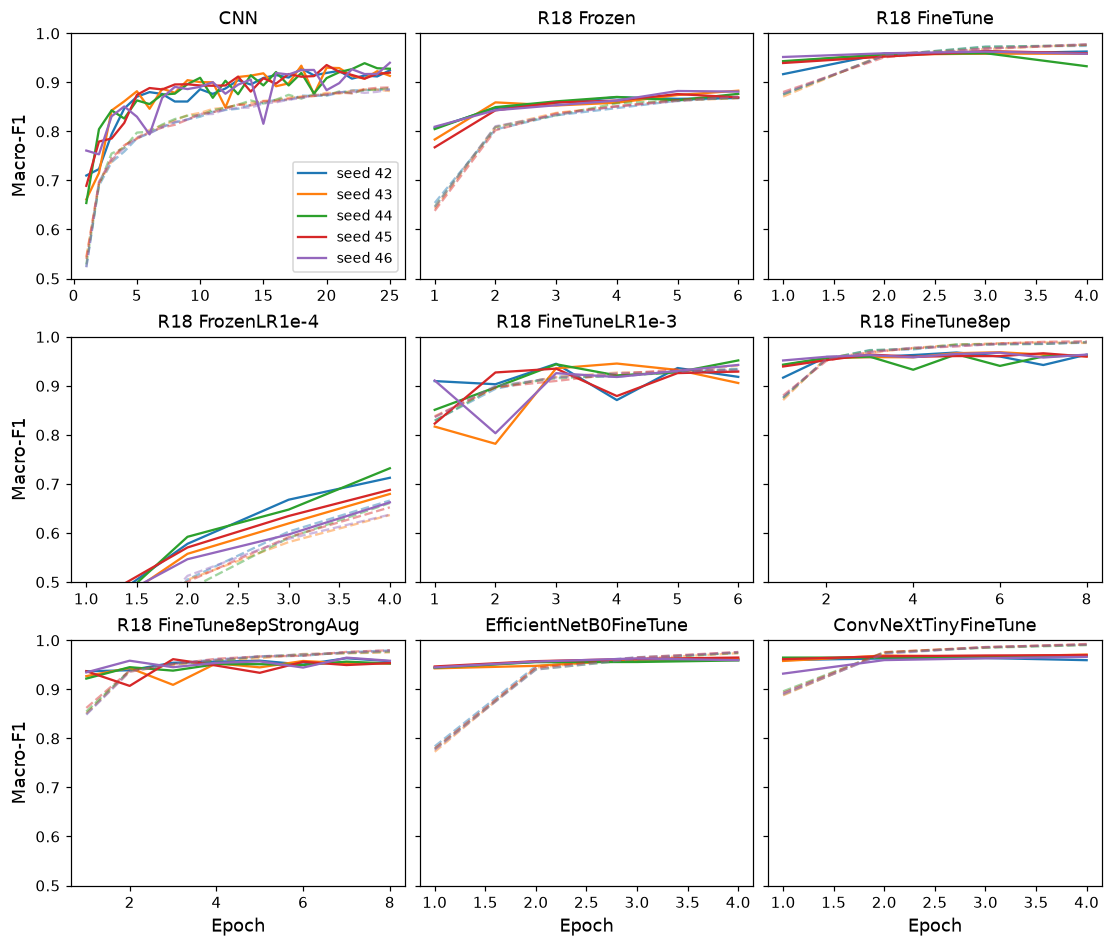

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(10, 8.5), sharey=True, layout="constrained")
for ax, model in zip(axes.ravel(), MODELS):
    for _, run in runs[runs["model"] == model].iterrows():
        history = pd.read_csv(OUTPUTS / run["folder"] / "history.csv")
        line = ax.plot(history["epoch"], history["val_macro_f1"], label=f"seed {run['seed']}")[0]
        ax.plot(history["epoch"], history["train_macro_f1"], "--", color=line.get_color(), alpha=0.45)
    ax.set_title(model.removeprefix("G_").replace("ResNet18", "R18 "))
    ax.set_ylim(0.5, 1)
for ax in axes[-1]:
    ax.set_xlabel("Epoch")
for ax in axes[:, 0]:
    ax.set_ylabel("Macro-F1")
axes[0, 0].legend(fontsize=9, loc="lower right")
plt.show()

### Observation

- Frozen at lr 1e-4: validation macro-F1 climbs slowly from below 0.5 and reaches only about 0.7 at epoch 4. A head trained alone needs the larger step.
- Full fine-tuning at lr 1e-3: the curves jump around (seed 46 drops to 0.80 at epoch 2, seed 42 to 0.87 at epoch 4). The large step disturbs the pretrained features.
- ResNet-18 with 8 epochs: training macro-F1 keeps rising to 0.99 while validation stays near 0.96, with a dip for seed 44. Overfitting is mild.
- Strong augmentation, 8 epochs: training macro-F1 stays below flip, and validation is noisier. Seed 43 drops at epoch 3.
- EfficientNet-B0 and ConvNeXt-T start above 0.93 validation macro-F1 after one epoch and change little after epoch 2.

## 6. Experiment 3: frozen vs full fine-tuning at the same schedule

Within each schedule the two runs differ only in which layers are trained. Runs with the same seed are compared in pairs.

In [9]:
rows = []
for (schedule, layers), model in E3.items():
    part = runs[runs["model"] == model]
    rows.append({"Schedule": schedule, "Trained layers": layers, "Run": model,
                 "Trainable": int(part["trainable"].iloc[0]),
                 "Val macro-F1": mean_sd(part["val_macro_f1"]), "Test macro-F1": mean_sd(part["test_macro_f1"]),
                 "Web-style acc.": mean_sd(part["web_accuracy"], 3), "256 x 256 acc.": mean_sd(part["lab_accuracy"]),
                 "Training minutes": mean_sd(part["fit_seconds"] / 60, 1)})
display(pd.DataFrame(rows).set_index(["Schedule", "Trained layers"]))

decisions = []
for schedule in ["lr 1e-3, 6 epochs", "lr 1e-4, 4 epochs"]:
    frozen = column(E3[(schedule, "frozen")], "test_macro_f1")
    full = column(E3[(schedule, "full")], "test_macro_f1")
    gap = full.mean() - frozen.mean()
    larger_sd = max(frozen.std(ddof=1), full.std(ddof=1))
    decisions.append({"Schedule": schedule, "Full - frozen (test macro-F1)": f"{gap:+.4f}",
                      "Paired change": mean_sd(full - frozen), "Seeds where full wins": f"{((full - frozen) > 0).sum()}/5",
                      "Larger SD": f"{larger_sd:.4f}", "Supported": gap > larger_sd})
pd.DataFrame(decisions).set_index("Schedule")

Run  Trainable  \
Schedule          Trained layers                                        
lr 1e-3, 6 epochs frozen                  G_ResNet18Frozen       4104   
                  full            G_ResNet18FineTuneLR1e-3   11180616   
lr 1e-4, 4 epochs frozen            G_ResNet18FrozenLR1e-4       4104   
                  full                  G_ResNet18FineTune   11180616   

                                     Val macro-F1    Test macro-F1  \
Schedule          Trained layers                                     
lr 1e-3, 6 epochs frozen          0.8776 ± 0.0054  0.8746 ± 0.0072   
                  full            0.9441 ± 0.0060  0.9424 ± 0.0034   
lr 1e-4, 4 epochs frozen          0.6949 ± 0.0275  0.7018 ± 0.0230   
                  full            0.9615 ± 0.0023  0.9583 ± 0.0023   

                                 Web-style acc.   256 x 256 acc.  \
Schedule          Trained layers                                   
lr 1e-3, 6 epochs frozen          0.307 ± 0.032  0.9403 ± 0.0049   
                  full            0.412 ± 0.032  0.9846 ± 0.0018   
lr 1e-4, 4 epochs frozen          0.222 ± 0.023  0.8418 ± 0.0081   
                  full            0.485 ± 0.023  0.9943 ± 0.0023   

                                 Training minutes  
Schedule          Trained layers                   
lr 1e-3, 6 epochs frozen                1.5 ± 0.1  
                  full                  2.2 ± 0.0  
lr 1e-4, 4 epochs frozen                1.0 ± 0.0  
                  full                  1.5 ± 0.0

,Full - frozen (test macro-F1),Paired change,Seeds where full wins,Larger SD,Supported
Schedule,,,,,
"lr 1e-3, 6 epochs",+0.0678,0.0678 ± 0.0088,5/5,0.0072,True
"lr 1e-4, 4 epochs",+0.2565,0.2565 ± 0.0216,5/5,0.0230,True


### Observation

Decision: supported at both schedules. Full fine-tuning beats the frozen backbone by 6.8 ± 0.9 points at (lr 1e-3, 6 epochs) and by 25.7 ± 2.2 points at (lr 1e-4, 4 epochs), in all 5 seeds each time.

So the gap seen in the main study (8.5 points on the CPU) is not caused by the different learning rate and budget. At the frozen model's own schedule the gap is still 6.8 points. The learning rate does interact with freezing: the frozen head needs lr 1e-3 (0.875 vs 0.702), while full fine-tuning prefers lr 1e-4 (0.958 vs 0.942). Each recipe of the main study was the better one for its model.

On web-style images the frozen model is also lower (0.307 vs 0.412 at the same schedule), so adapting the features helps both lab and field photos.

## 7. Experiment 4: augmentation with an 8-epoch budget

The decision rule is the one of Experiment 2: the hypothesis is supported if the mean paired gain in web-style accuracy is larger than the seed SD of the baseline and overall test macro-F1 drops by no more than 0.5 points.

In [10]:
METRICS = {"Test macro-F1": "test_macro_f1", "Accuracy web-style": "web_accuracy", "Accuracy 256 x 256": "lab_accuracy"}
rows = []
for label, name in METRICS.items():
    baseline, ablation = column(E4_BASELINE, name), column(E4_ABLATION, name)
    change = ablation - baseline
    rows.append({"Metric": label, "Flip, 8 epochs": mean_sd(baseline), "Strong, 8 epochs": mean_sd(ablation),
                 "Paired change (strong - flip)": mean_sd(change), "Seeds improved": f"{(change > 0).sum()}/{len(change)}"})
display(pd.DataFrame(rows).set_index("Metric"))

web_change = column(E4_ABLATION, "web_accuracy") - column(E4_BASELINE, "web_accuracy")
f1_change = column(E4_ABLATION, "test_macro_f1") - column(E4_BASELINE, "test_macro_f1")
baseline_web_sd = column(E4_BASELINE, "web_accuracy").std(ddof=1)
print(f"Web-style accuracy change: {web_change.mean():+.4f} (must be above the baseline SD {baseline_web_sd:.4f})")
print(f"Overall macro-F1 change:   {f1_change.mean():+.4f} (must be at least {-F1_TOLERANCE:+.4f})")
supported = web_change.mean() > baseline_web_sd and f1_change.mean() >= -F1_TOLERANCE
print("Decision: hypothesis", "SUPPORTED" if supported else "NOT SUPPORTED", "on", len(web_change), "paired seeds")
(web_change * web.sum()).round().astype(int).rename("Web-style images gained (negative = lost)").to_frame().T

,"Flip, 8 epochs","Strong, 8 epochs",Paired change (strong - flip),Seeds improved
Metric,,,,
Test macro-F1,0.9634 ± 0.0030,0.9526 ± 0.0075,-0.0108 ± 0.0075,1/5
Accuracy web-style,0.5098 ± 0.0264,0.4659 ± 0.0642,-0.0439 ± 0.0725,1/5
Accuracy 256 x 256,0.9972 ± 0.0009,0.9902 ± 0.0030,-0.0070 ± 0.0032,0/5


Web-style accuracy change: -0.0439 (must be above the baseline SD 0.0264)
Overall macro-F1 change:   -0.0108 (must be at least -0.0050)
Decision: hypothesis NOT SUPPORTED on 5 paired seeds


seed,42,43,44,45,46
Web-style images gained (negative = lost),-8,0,-9,-6,5


In [11]:
# does the longer budget change the 4-epoch picture? same recipe, 4 vs 8 epochs
rows = []
for label, model in [("Flip, 4 epochs", "G_ResNet18FineTune"), ("Flip, 8 epochs", E4_BASELINE), ("Strong, 8 epochs", E4_ABLATION)]:
    part = runs[runs["model"] == model]
    rows.append({"Run": label, "Selected epochs": ", ".join(map(str, part["best_epoch"])),
                 "Train macro-F1": mean_sd(part["train_macro_f1"]), "Test macro-F1": mean_sd(part["test_macro_f1"]),
                 "Web-style acc.": mean_sd(part["web_accuracy"], 3)})
pd.DataFrame(rows).set_index("Run")

,Selected epochs,Train macro-F1,Test macro-F1,Web-style acc.
Run,,,,
"Flip, 4 epochs","4, 3, 3, 3, 3",0.9818 ± 0.0033,0.9583 ± 0.0023,0.485 ± 0.023
"Flip, 8 epochs","5, 6, 5, 7, 6",0.9919 ± 0.0008,0.9634 ± 0.0030,0.510 ± 0.026
"Strong, 8 epochs","7, 6, 7, 3, 7",0.9798 ± 0.0066,0.9526 ± 0.0075,0.466 ± 0.064


### Observation

Decision: not supported. With 8 epochs, strong augmentation still lowers web-style accuracy (0.510 to 0.466, -4.4 ± 7.3 points) and macro-F1 (-1.1 ± 0.8 points). It is better than flip in only one seed (46, +5 web-style images); the other seeds lose 0 to 9 images.

The longer budget was not the reason Experiment 2 failed. With 8 epochs the strong-augmentation runs do select later epochs (6 to 7 in four seeds), so they had time to converge. The doubled budget helps plain flip instead: test macro-F1 rises from 0.958 to 0.963 and web-style accuracy from 0.485 to 0.510.

The SD of web-style accuracy with strong augmentation is large (0.064), so the result is less stable than with flip. Generic crops and colour jitter do not look like field photos, which is the likely reason.

## 8. Experiment 5: backbone A vs B

Three ImageNet-pretrained backbones, each fully fine-tuned with the same recipe (lr 1e-4, 4 epochs, flip, Adam, batch 64).

In [12]:
rows = []
for label, model in E5.items():
    part = runs[runs["model"] == model]
    rows.append({"Backbone": label, "Parameters": int(part["parameters"].iloc[0]),
                 "Test accuracy": mean_sd(part["test_accuracy"]), "Test macro-F1": mean_sd(part["test_macro_f1"]),
                 "Clean macro-F1": mean_sd(part["clean_macro_f1"]), "Web-style acc.": mean_sd(part["web_accuracy"], 3),
                 "256 x 256 acc.": mean_sd(part["lab_accuracy"])})
display(pd.DataFrame(rows).set_index("Backbone"))

reference = column(E5["ResNet-18"], "test_macro_f1")
reference_web = column(E5["ResNet-18"], "web_accuracy")
rows = []
for label in ["EfficientNet-B0", "ConvNeXt-T"]:
    other = column(E5[label], "test_macro_f1")
    other_web = column(E5[label], "web_accuracy")
    larger_sd = max(reference.std(ddof=1), other.std(ddof=1))
    rows.append({"Backbone vs ResNet-18": label, "Macro-F1 difference": f"{other.mean() - reference.mean():+.4f}",
                 "Larger SD": f"{larger_sd:.4f}", "Beyond the larger SD": abs(other.mean() - reference.mean()) > larger_sd,
                 "Seeds better": f"{((other - reference) > 0).sum()}/5",
                 "Web-style difference": f"{other_web.mean() - reference_web.mean():+.3f}",
                 "Web-style seeds better": f"{((other_web - reference_web) > 0).sum()}/5"})
pd.DataFrame(rows).set_index("Backbone vs ResNet-18")

,Parameters,Test accuracy,Test macro-F1,Clean macro-F1,Web-style acc.,256 x 256 acc.
Backbone,,,,,,
ResNet-18,11180616,0.9710 ± 0.0016,0.9583 ± 0.0023,0.9594 ± 0.0026,0.485 ± 0.023,0.9943 ± 0.0023
EfficientNet-B0,4017796,0.9769 ± 0.0020,0.9666 ± 0.0033,0.9677 ± 0.0033,0.549 ± 0.021,0.9974 ± 0.0013
ConvNeXt-T,27826280,0.9790 ± 0.0021,0.9695 ± 0.0015,0.9705 ± 0.0014,0.615 ± 0.037,0.9964 ± 0.0024


,Macro-F1 difference,Larger SD,Beyond the larger SD,Seeds better,Web-style difference,Web-style seeds better
Backbone vs ResNet-18,,,,,,
EfficientNet-B0,+0.0083,0.0033,True,5/5,+0.063,5/5
ConvNeXt-T,+0.0111,0.0023,True,5/5,+0.129,5/5


In [13]:
per_class = pd.DataFrame(index=pd.Index(NAMES, name="Class"))
for label, model in E5.items():
    scores = np.array([f1_score(labels, predictions[(model, seed)]["predictions"], labels=range(8), average=None,
                                zero_division=0) for seed in seeds_of(model)])
    per_class[label] = [mean_sd(scores[:, c], 3) for c in range(8)]
per_class["Test images"] = np.bincount(labels, minlength=8)
per_class

,ResNet-18,EfficientNet-B0,ConvNeXt-T,Test images
Class,,,,
Bacterial spot,0.966 ± 0.008,0.970 ± 0.004,0.969 ± 0.007,241
Early blight,0.922 ± 0.016,0.957 ± 0.010,0.954 ± 0.009,117
Late blight,0.964 ± 0.008,0.973 ± 0.005,0.976 ± 0.004,209
Leaf mold,0.935 ± 0.009,0.941 ± 0.009,0.956 ± 0.007,125
Septoria leaf spot,0.963 ± 0.008,0.976 ± 0.009,0.967 ± 0.009,223
Tomato yellow leaf curl virus,0.994 ± 0.002,0.994 ± 0.001,0.997 ± 0.002,625
Tomato mosaic virus,0.940 ± 0.007,0.941 ± 0.011,0.947 ± 0.009,59
Healthy,0.982 ± 0.006,0.981 ± 0.004,0.991 ± 0.002,197


### Observation

Decision: supported for both backbones. ConvNeXt-T beats ResNet-18 by 1.1 points of macro-F1 (larger SD 0.2) and EfficientNet-B0 by 0.8 points (larger SD 0.3), in all 5 seeds.

The gain is much larger on web-style photos: +12.9 points for ConvNeXt-T (0.485 to 0.615) and +6.3 points for EfficientNet-B0, again in 5 of 5 seeds. On lab images all three are above 99.4%.

EfficientNet-B0 gets this with 4.0M parameters, 2.8 times fewer than ResNet-18. ConvNeXt-T needs 27.8M. Per class, the newer backbones help most on Early blight (0.922 to 0.957 and 0.954) and Leaf mold (0.935 to 0.956 for ConvNeXt-T). Tomato mosaic virus stays the weakest class for all three (0.940 to 0.947).

## 9. Error groups for the three backbones

The same five groups as in `02_results.ipynb`; each error goes to the first group that matches.

In [14]:
GROUPS = ["Web-style photo", "Conflicting near-duplicate", "Virus confusion", "Spot / blight confusion", "Other"]
VIRUS = [NAMES.index("Tomato mosaic virus"), NAMES.index("Tomato yellow leaf curl virus")]
SPOT = [NAMES.index(name) for name in ["Bacterial spot", "Early blight", "Late blight", "Septoria leaf spot"]]


def error_group(i, predicted_class):
    true_class = labels[i]
    if web[i]:
        return "Web-style photo"
    if conflict[i]:
        return "Conflicting near-duplicate"
    if true_class in VIRUS and predicted_class in VIRUS:
        return "Virus confusion"
    if true_class in SPOT and predicted_class in SPOT:
        return "Spot / blight confusion"
    return "Other"


def error_groups(predicted):
    return np.array(["" if predicted[i] == labels[i] else error_group(i, predicted[i]) for i in range(len(labels))])


taxonomy = pd.DataFrame(index=pd.Index(GROUPS + ["All errors"], name="Errors per seed"))
for label, model in E5.items():
    counts = np.array([[np.sum(error_groups(predictions[(model, seed)]["predictions"]) == group) for group in GROUPS]
                       for seed in seeds_of(model)])
    taxonomy[label] = [mean_sd(counts[:, k], 1) for k in range(len(GROUPS))] + [mean_sd(counts.sum(axis=1), 1)]
taxonomy

,ResNet-18,EfficientNet-B0,ConvNeXt-T
Errors per seed,,,
Web-style photo,42.2 ± 1.9,37.0 ± 1.7,31.6 ± 3.0
Conflicting near-duplicate,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0
Virus confusion,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0
Spot / blight confusion,7.6 ± 3.8,2.2 ± 1.9,5.0 ± 2.0
Other,2.2 ± 0.8,2.2 ± 0.8,1.2 ± 2.7
All errors,52.0 ± 2.8,41.4 ± 3.5,37.8 ± 3.7


### Observation

ConvNeXt-T makes 37.8 errors per seed, against 52.0 for ResNet-18. Most of the difference is on web-style photos (42.2 to 31.6 per seed). Spot / blight confusion is lowest for EfficientNet-B0 (2.2 per seed). Virus confusion and conflicting near-duplicates cause no errors for these three models. Web-style photos are still the largest group for every backbone: 84% of ConvNeXt-T errors.

## 10. Web-style photos: where the backbones agree and disagree

Seed 42 of ResNet-18 and ConvNeXt-T. Each web-style test image falls into one of four cells.

In [15]:
SEED = 42
resnet_correct = predictions[(E5["ResNet-18"], SEED)]["predictions"] == labels
convnext_predicted = predictions[(E5["ConvNeXt-T"], SEED)]["predictions"]
convnext_confidence = predictions[(E5["ConvNeXt-T"], SEED)]["probabilities"].max(axis=1)
convnext_correct = convnext_predicted == labels
display(pd.crosstab(pd.Series(resnet_correct[web], name="ResNet-18 correct"),
                    pd.Series(convnext_correct[web], name="ConvNeXt-T correct")))

# web-style images every seed of every backbone gets wrong
all_wrong = web.copy()
for model in E5.values():
    for seed in seeds_of(model):
        all_wrong &= predictions[(model, seed)]["predictions"] != labels
print("Web-style images wrong for all 3 backbones x 5 seeds:", int(all_wrong.sum()), "of", int(web.sum()))

ConvNeXt-T correct,False,True
ResNet-18 correct,,
False,30,9
True,7,36


Web-style images wrong for all 3 backbones x 5 seeds: 8 of 82


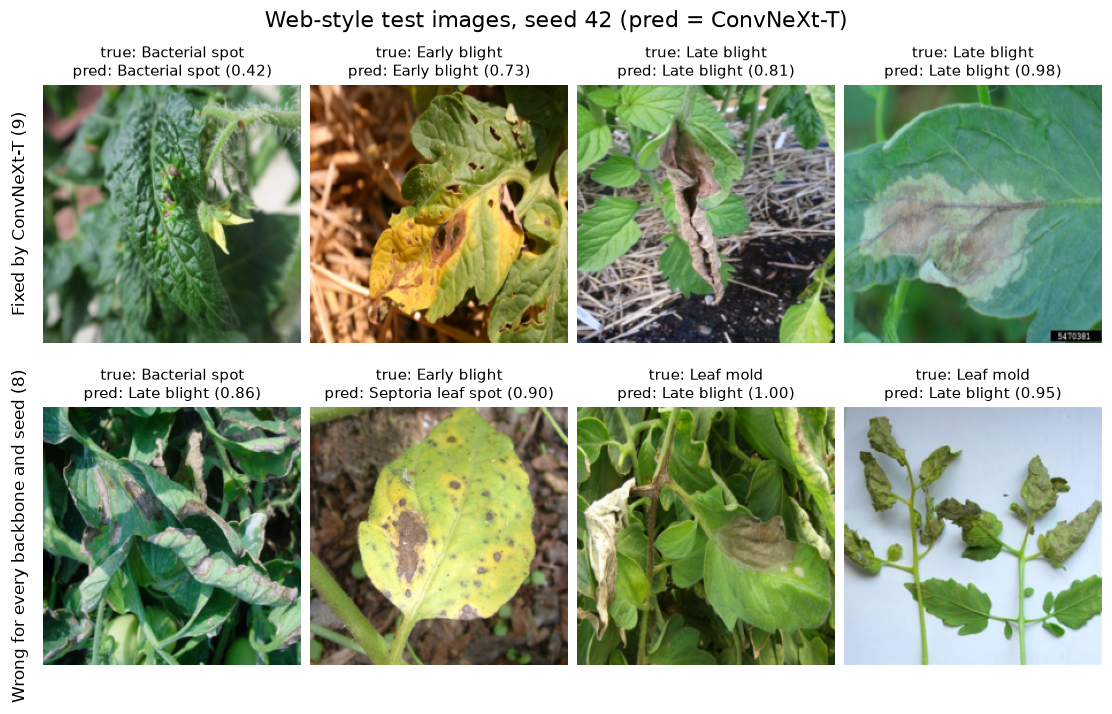

In [16]:
groups = [("Fixed by ConvNeXt-T", np.where(web & ~resnet_correct & convnext_correct)[0]),
          ("Wrong for every backbone and seed", np.where(all_wrong)[0])]
fig, axes = plt.subplots(2, 4, figsize=(10, 6.4), layout="constrained")
for row, (title, members) in enumerate(groups):
    for column_index in range(4):
        ax = axes[row, column_index]
        ax.axis("off")
        if column_index < len(members):
            i = members[column_index]
            ax.imshow(test_images[i])
            ax.set_title(f"true: {NAMES[labels[i]]}\npred: {NAMES[convnext_predicted[i]]} ({convnext_confidence[i]:.2f})",
                         fontsize=10)
    axes[row, 0].text(-0.06, 0.5, f"{title} ({len(members)})", transform=axes[row, 0].transAxes,
                      rotation=90, ha="right", va="center", fontsize=11)
fig.suptitle(f"Web-style test images, seed {SEED} (pred = ConvNeXt-T)")
plt.show()

### Observation

For seed 42, ConvNeXt-T fixes 9 web-style images that ResNet-18 gets wrong and breaks 7 that ResNet-18 gets right, so the net gain in this seed is only 2 images. Over the 5 seeds the gain is larger (about 10.6 images per seed on average, from the error table).

The fixed images show one leaf or one lesion large in the frame (Late blight patches, an Early blight leaf). 8 of the 82 web-style images are wrong for every backbone and every seed. They show many overlapping leaves, fruit, or a plant on a white background (Leaf mold predicted as Late blight with confidence 1.00). Some of these may be hard even for a person without the source label.

## 11. Compute cost

GPU: one NVIDIA A40 per run, one run per card. Training time covers all epochs including validation. GPU inference time is milliseconds per test image including data loading (median of two passes after one warm-up).

The CPU latency column loads the seed-42 checkpoint of each backbone on the CPU with the thread count of the main study and times 512 test images in batches of 64, with the same rule (one warm-up, median of two passes), so it can be read next to the CPU table in `02_results.ipynb`.

In [17]:
def cpu_inference_ms(model_name, seed=42, count=512):
    folder = runs.loc[(runs["model"] == model_name) & (runs["seed"] == seed), "folder"].iloc[0]
    saved = torch.load(OUTPUTS / folder / "best.pt", map_location="cpu", weights_only=True)
    network = RUNS[model_name]["build"]()
    network.load_state_dict(saved["model_state"])
    network.eval()
    torch.set_num_threads(THREADS)
    loader = torch.utils.data.DataLoader(TomatoDataset(test_images[:count], labels[:count]), batch_size=64)
    durations = []
    with torch.inference_mode():
        for repeat in range(3):
            start = time.perf_counter()
            for batch, _ in loader:
                network(batch).argmax(1)
            if repeat:
                durations.append(time.perf_counter() - start)
    return float(np.median(durations) * 1000 / count)


rows = []
for model in MODELS:
    part = runs[runs["model"] == model]
    rows.append({"Run": model, "Parameters": int(part["parameters"].iloc[0]), "Trainable": int(part["trainable"].iloc[0]),
                 "Epochs": int(part["epochs_run"].iloc[0]),
                 "Seconds per epoch": mean_sd(part["median_epoch_seconds"], 1),
                 "Training minutes": mean_sd(part["fit_seconds"] / 60, 2),
                 "GPU inference ms/image": mean_sd(part["test_ms"], 3), "Test macro-F1": mean_sd(part["test_macro_f1"])})
cost = pd.DataFrame(rows).set_index("Run")
cost["CPU inference ms/image (seed 42)"] = ""
for model in ["G_CNN", "G_ResNet18FineTune", "G_EfficientNetB0FineTune", "G_ConvNeXtTinyFineTune"]:
    cost.loc[model, "CPU inference ms/image (seed 42)"] = f"{cpu_inference_ms(model):.2f}"
cost

,Parameters,Trainable,Epochs,Seconds per epoch,Training minutes,GPU inference ms/image,Test macro-F1,CPU inference ms/image (seed 42)
Run,,,,,,,,
G_CNN,61384,61384,25,12.3 ± 0.7,5.24 ± 0.32,0.493 ± 0.007,0.9292 ± 0.0084,1.76
G_ResNet18Frozen,11180616,4104,6,15.1 ± 1.5,1.53 ± 0.14,0.519 ± 0.003,0.8746 ± 0.0072,
G_ResNet18FineTune,11180616,11180616,4,21.8 ± 0.5,1.49 ± 0.04,0.517 ± 0.010,0.9583 ± 0.0023,10.21
G_ResNet18FrozenLR1e-4,11180616,4104,4,14.8 ± 0.5,1.01 ± 0.04,0.527 ± 0.010,0.7018 ± 0.0230,
G_ResNet18FineTuneLR1e-3,11180616,11180616,6,22.1 ± 0.4,2.23 ± 0.04,0.516 ± 0.009,0.9424 ± 0.0034,
G_ResNet18FineTune8ep,11180616,11180616,8,22.7 ± 0.7,3.05 ± 0.10,0.555 ± 0.047,0.9634 ± 0.0030,
G_ResNet18FineTune8epStrongAug,11180616,11180616,8,70.1 ± 1.3,9.56 ± 0.52,0.515 ± 0.005,0.9526 ± 0.0075,
G_EfficientNetB0FineTune,4017796,4017796,4,34.4 ± 0.8,2.32 ± 0.05,0.595 ± 0.015,0.9666 ± 0.0033,18.12
G_ConvNeXtTinyFineTune,27826280,27826280,4,79.9 ± 2.3,5.33 ± 0.14,1.116 ± 0.006,0.9695 ± 0.0015,35.21


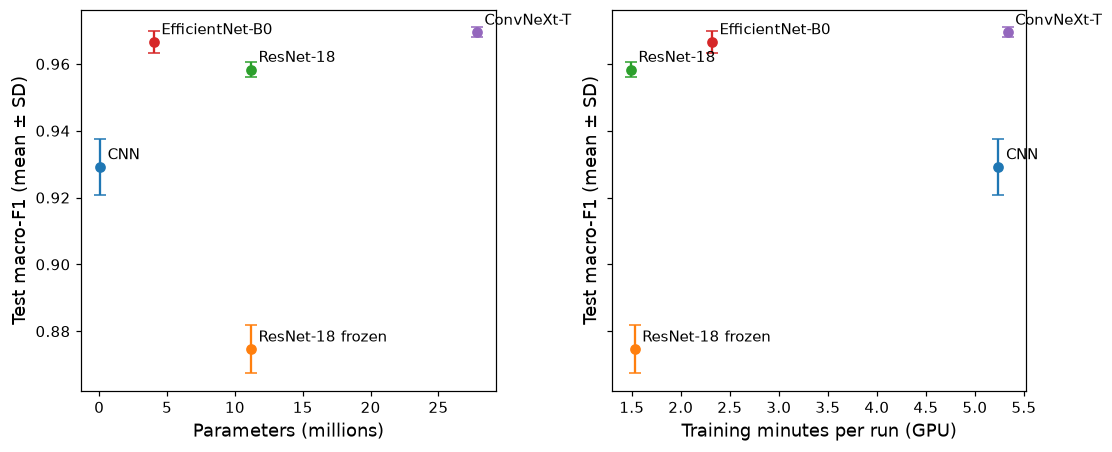

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, layout="constrained")
for label, model in [("CNN", "G_CNN"), ("ResNet-18 frozen", "G_ResNet18Frozen")] + list(E5.items()):
    part = runs[runs["model"] == model]
    f1_mean, f1_sd = part["test_macro_f1"].mean(), part["test_macro_f1"].std(ddof=1)
    for ax, x in zip(axes, [part["parameters"].iloc[0] / 1e6, part["fit_seconds"].mean() / 60]):
        ax.errorbar(x, f1_mean, yerr=f1_sd, fmt="o", capsize=4)
        ax.annotate(label, (x, f1_mean), textcoords="offset points", xytext=(5, 5), fontsize=10)
axes[0].set_xlabel("Parameters (millions)")
axes[1].set_xlabel("Training minutes per run (GPU)")
for ax in axes:
    ax.set_ylabel("Test macro-F1 (mean ± SD)")
plt.show()

### Observation

Training on one A40 takes 1.5 minutes for ResNet-18 fine-tuning (4 epochs), 2.3 minutes for EfficientNet-B0 and 5.3 minutes for ConvNeXt-T, against 39 minutes for ResNet-18 on the CPU. Strong augmentation is the slowest ResNet-18 run per epoch (70 s against 23 s), because its transforms run on the CPU, one image at a time.

GPU inference is about 0.5 ms per image for the CNN and all ResNet-18 runs, and 0.6 and 1.1 ms for EfficientNet-B0 and ConvNeXt-T. The CNN is not faster than ResNet-18 here: with zero DataLoader workers the time is mostly batch loading and normalisation on the CPU, not the network.

CPU latency (this machine, AMD EPYC, 14 threads, seed 42 only): CNN 1.8 ms, ResNet-18 10.2 ms, EfficientNet-B0 18.1 ms, ConvNeXt-T 35.2 ms per image. The machine is shared with other users: over three executions of this notebook the values moved by up to 30% (EfficientNet-B0 from 13.9 to 18.1 ms), but the order never changed. This CPU is also faster than the one of the main study (ResNet-18: 10.2 vs 23.4 ms), so only the ratios should be compared. EfficientNet-B0 has fewer parameters than ResNet-18 but is slower on the CPU, because depthwise convolutions do little work per memory access. ConvNeXt-T is about 3.5 times slower than ResNet-18 for +1.1 points of macro-F1 and +12.9 points on web-style photos.

## 12. Conclusion

- Hardware: the GPU copies reproduce the CPU means within one seed SD.
- Experiment 3: freezing itself causes the gap. Full fine-tuning wins by 6.8 points at the frozen model's schedule and by 25.7 points at the fine-tuning schedule.
- Experiment 4: strong augmentation still does not help with 8 epochs. A longer budget helps plain fine-tuning (0.958 to 0.963).
- Experiment 5: a newer backbone is the only change in this project that clearly reduces the domain gap. ConvNeXt-T reaches 0.970 macro-F1 and 61.5% on web-style photos (ResNet-18: 48.5%). EfficientNet-B0 is the best trade-off for size (4.0M parameters, 0.967).
- Still open: about 38% of web-style photos are wrong even for ConvNeXt-T, and 8 of 82 are wrong for every model. Field images in training would be the next step.